**Medical Aid Text Analysis**
Done by: Luthando-Lwethu Mtshali

**1. Model choice and jusfication**


*   The client needs to find broad areas of concern: the model type is unsupervised topic modelling and the model utilised is LDA (Late Dirichlet Allocation) on negative reviews. The reason it is being used is because there are no labelled "concern"categories that are present. LDA finds repeated themes from word co-occurrence and provides interpretable word lists with each topic.

*   The client needs to analyse customer seniment, with the model type being supervised text classification. The specific model is TF-IDF + Logistic Regression (compare to mulinomial naive Bayes). The reason it is being used is because star ratings provide labels which are either positive or negative. Logistic regression is a potent, quick text baseline and its coefficients display which words drive sentiment, which is suitable for a client report.

**2. Dataset choice and justification**

*   The dataset that will be used is the UCI ML Drug Review Dataset
* It is a large dataset with 215k reviews, so the model can generalise and anomaly themes can still be identified
* Real life patient-written text, matching the clients real-world review data
* Each review shows a rating that is a numerical value so there are labels for sentiment without manual labelling being needed
* The data is of the medical field with patients comments being on service related situations the medical aid scheme values: side effects, effectiveness, cost, accessibility,and doctors.










**4. Analysis Plan**


*   EDA and cleaning: Check shape, types, nulls, duplicate records. eliminate polluted conditions and HTML entities. plot rating spread, review length, top conditions, reviews per annum. Make sentiment label from rating. Compare word frequencies between positive and negative reviews.

*  Feature Selection: TF-IDF features (unigrams and bigrams). Chi-square test p-values (p<0.05) then retain the top k features. examine logistic regression coefficients for interpretation.

* Train model: LDA:k = 4 to 10 topics, pick by coherance/perplexity and interpretability. classifier baseline: TF-IDF 5000 features, logistic regression, C=1

* Interpret and evaluate: Use accuracy, precision, recall, F1 (macro and per class), confusion matrix, ROC-AUC. F1 is important because classes are not balanced.

* Retrain: GridSearchCV over C, n-grams, number of features, class weight. Compare against baseline and describe transformations.




In [1]:
import os
import re, html
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import nltk
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer


from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.feature_extraction.text import TfidfVectorizer, CountVectorizer
from sklearn.feature_selection import SelectKBest, chi2
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import MultinomialNB
from sklearn.pipeline import Pipeline
from sklearn.decomposition import LatentDirichletAllocation
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             classification_report, confusion_matrix, roc_auc_score,
                             roc_curve, ConfusionMatrixDisplay)
nltk.download ('stopwords')
nltk.download ('wordnet')
nltk.download('omw-1.4')

sns.set_theme(style='whitegrid')
RANDOM_STATE = 42 # fixed seed so results are reproducible



[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Unzipping corpora/stopwords.zip.
[nltk_data] Downloading package wordnet to /root/nltk_data...
[nltk_data] Downloading package omw-1.4 to /root/nltk_data...


In [2]:
# Cell 2: Load data (downloads from Kaggle automatically)
%pip install -q kagglehub

import os, glob
import kagglehub
import pandas as pd

# Download the dataset (cached, so re-running is fast)
path = kagglehub.dataset_download("jessicali9530/kuc-hackathon-winter-2018")
print('Downloaded to:', path)

def find_file(stem):
    """Search for drugsComTrain_raw / drugsComTest_raw anywhere sensible."""
    for root in [path, '/content', os.path.expanduser('~/.cache/kagglehub')]:
        hits = [h for h in glob.glob(f'{root}/**/{stem}.*', recursive=True)
                if h.endswith(('.csv', '.tsv'))]
        if hits:
            return hits[0]
    raise FileNotFoundError(f'Could not find {stem}')

def load(stem):
    f = find_file(stem)
    print('Loading:', f)
    return pd.read_csv(f, sep='\t' if f.endswith('.tsv') else ',')

train_raw = load('drugsComTrain_raw')
test_raw = load('drugsComTest_raw')

print('Train shape:', train_raw.shape)
print('Test shape:', test_raw.shape)
train_raw.head()

Using Colab cache for faster access to the 'kuc-hackathon-winter-2018' dataset.
Downloaded to: /kaggle/input/kuc-hackathon-winter-2018
Loading: /kaggle/input/kuc-hackathon-winter-2018/drugsComTrain_raw.csv
Loading: /kaggle/input/kuc-hackathon-winter-2018/drugsComTest_raw.csv
Train shape: (161297, 7)
Test shape: (53766, 7)


,uniqueID,drugName,condition,review,rating,date,usefulCount
0,206461,Valsartan,Left Ventricular Dysfunction,"""It has no side effect, I take it in combinati...",9,20-May-12,27
1,95260,Guanfacine,ADHD,"""My son is halfway through his fourth week of ...",8,27-Apr-10,192
2,92703,Lybrel,Birth Control,"""I used to take another oral contraceptive, wh...",5,14-Dec-09,17
3,138000,Ortho Evra,Birth Control,"""This is my first time using any form of birth...",8,3-Nov-15,10
4,35696,Buprenorphine / naloxone,Opiate Dependence,"""Suboxone has completely turned my life around...",9,27-Nov-16,37


In [3]:
# Data types and non-null counts
train_raw.info()
# Missing values per column
print('\nMissing values:\n', train_raw.isnull().sum())
# Duplicate rows (ignoring the ID column)
print('\nDuplicates:', train_raw.drop(columns='uniqueID').duplicated().sum())
# Summary statistics for numeric columns
print(train_raw[['rating', 'usefulCount']].describe())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 161297 entries, 0 to 161296
Data columns (total 7 columns):
 #   Column       Non-Null Count   Dtype 
---  ------       --------------   ----- 
 0   uniqueID     161297 non-null  int64 
 1   drugName     161297 non-null  object
 2   condition    160398 non-null  object
 3   review       161297 non-null  object
 4   rating       161297 non-null  int64 
 5   date         161297 non-null  object
 6   usefulCount  161297 non-null  int64 
dtypes: int64(3), object(4)
memory usage: 8.6+ MB

Missing values:
 uniqueID         0
drugName         0
condition      899
review           0
rating           0
date             0
usefulCount      0
dtype: int64

Duplicates: 0
              rating    usefulCount
count  161297.000000  161297.000000
mean        6.994377      28.004755
std         3.272329      36.403742
min         1.000000       0.000000
25%         5.000000       6.000000
50%         8.000000      16.000000
75%        10.000000      36.00

In [4]:
# Stopwords: we KEEP negation words because 'not good' flips sentiment
stop_words = set(stopwords.words('english')) - {'no', 'not', 'nor', "don't", 'never', "didn't", "doesn't", "won't"}
lemmatizer = WordNetLemmatizer()

def clean_text(text):
    """Clean one review: decode HTML, lowercase, keep letters only, remove stopwords, lemmatise."""
    text = html.unescape(str(text))
    text = text.lower()
    text = re.sub(r'<.*?>', ' ', text)
    text = re.sub(r'[^a-z\s]', ' ', text)
    # keep letters only
    tokens = [lemmatizer.lemmatize(w) for w in text.split() if w not in stop_words and len(w) > 2]
    return ' '.join(tokens)

def prepare(df):
    df = df.copy()
    # remove rows that do not have text or rating
    df = df.dropna(subset=['review', 'rating'])

    df['condition'] = df['condition'].fillna('Unknown')
    # Some conditions are polluted with 'users found this comment helpful'
    df.loc[df['condition'].str.contains('users found', na=False), 'condition'] = 'Unknown'

    # eliminate repeated reviews
    df = df.drop_duplicates(subset=['drugName', 'condition', 'review'])
    df['date'] = pd.to_datetime(df['date'], errors='coerce')
    df['year'] = df['date'].dt.year

    # raw length for EDA
    df['review_len_words'] = df['review'].str.split().str.len()

    df['clean_review'] = df['review'].apply(clean_text)
    # drop reviews empty after cleaning
    df = df[df['clean_review'].str.len() > 0]

    # Sentiment label from rating: <=4 negative, >=7 positive, 5-6 neutral (excluded below)
    df['sentiment'] = np.where(df['rating'] <= 4, 'negative', np.where(df['rating'] >= 7, 'positive', 'neutral'))
    return df.reset_index(drop=True)

train = prepare(train_raw)
test = prepare(test_raw)

print('After cleaning:', train.shape, test.shape)
print('Rows removed from train:', len(train_raw) - len(train))
train[['review', 'clean_review', 'rating', 'sentiment']].head()

/tmp/ipykernel_425/3696313469.py:26: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  df['date'] = pd.to_datetime(df['date'], errors='coerce')
/tmp/ipykernel_425/3696313469.py:26: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  df['date'] = pd.to_datetime(df['date'], errors='coerce')


After cleaning: (161235, 11) (53752, 11)
Rows removed from train: 62


,review,clean_review,rating,sentiment
0,"""It has no side effect, I take it in combinati...",side effect take combination bystolic fish oil,9,positive
1,"""My son is halfway through his fourth week of ...",son halfway fourth week intuniv became concern...,8,positive
2,"""I used to take another oral contraceptive, wh...",used take another oral contraceptive pill cycl...,5,neutral
3,"""This is my first time using any form of birth...",first time using form birth control glad went ...,8,positive
4,"""Suboxone has completely turned my life around...",suboxone completely turned life around feel he...,9,positive


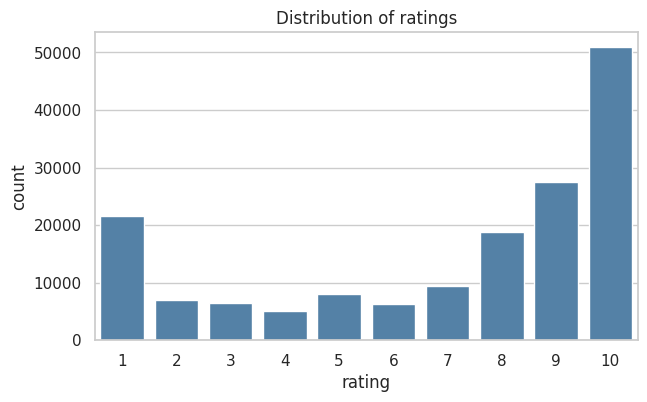

sentiment
positive    0.663
negative    0.248
neutral     0.089
Name: proportion, dtype: float64


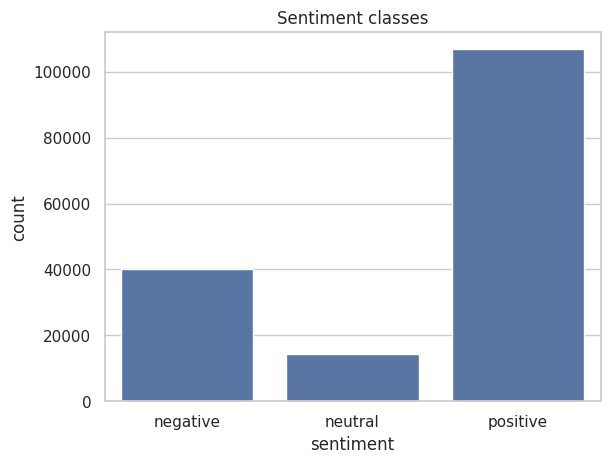

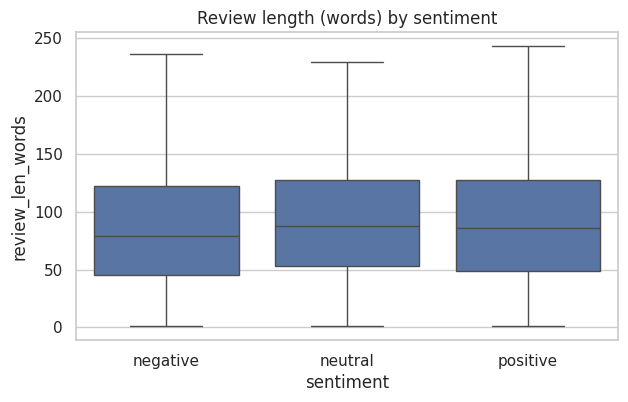

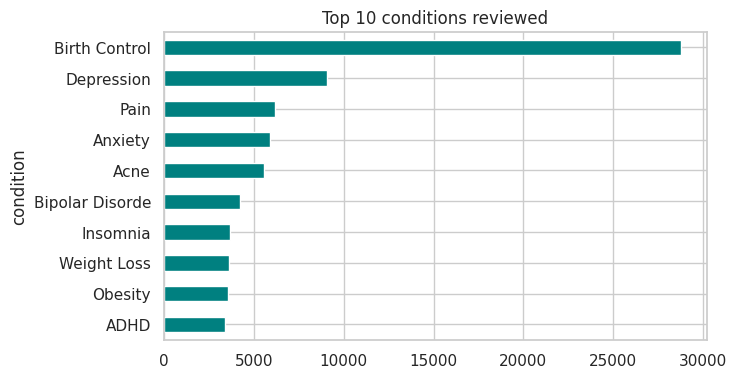

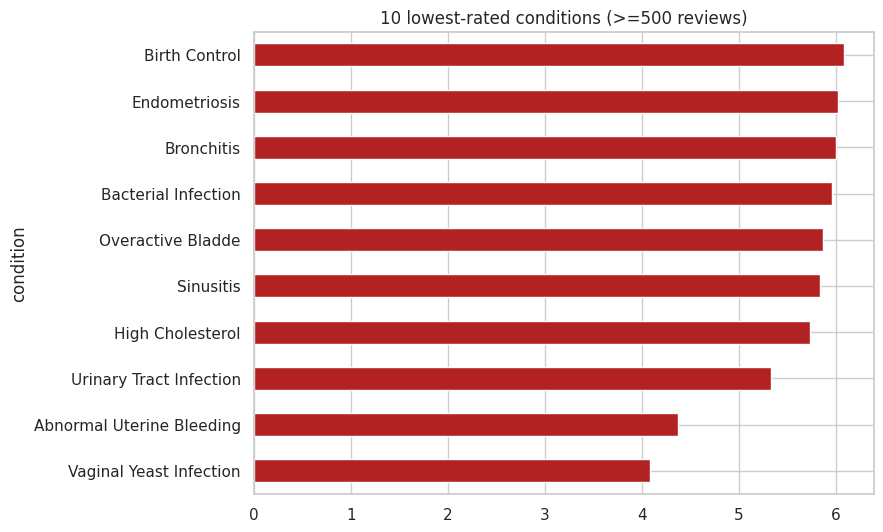

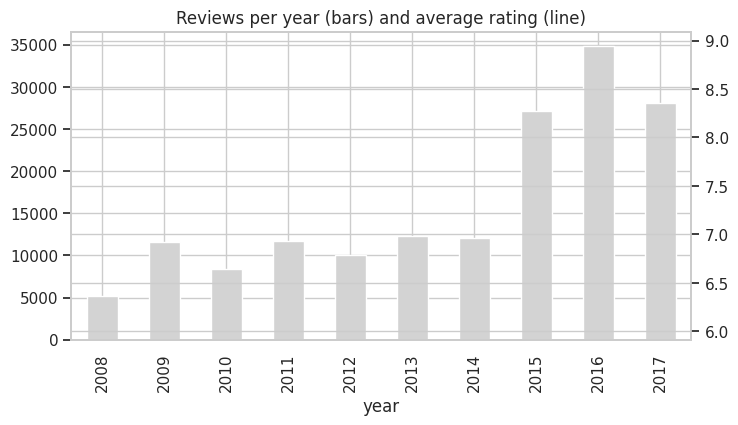

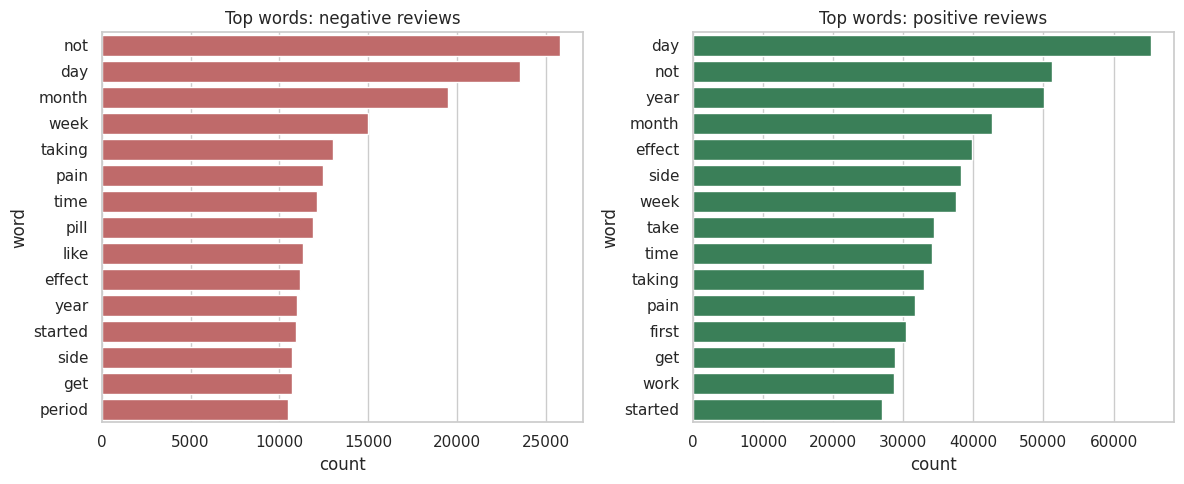

sentiment
negative    16.0
neutral     18.6
positive    33.8
Name: usefulCount, dtype: float64


In [5]:
 # 5a. Rating distribution
plt.figure(figsize=(7,4))
sns.countplot(x='rating', data=train, color='steelblue')
plt.title('Distribution of ratings'); plt.show()

# 5b. Sentiment class balance
print(train['sentiment'].value_counts(normalize=True).round(3))
sns.countplot(x='sentiment', data=train, order=['negative','neutral','positive'])
plt.title('Sentiment classes'); plt.show()

# 5c. Review length by sentiment
plt.figure(figsize=(7,4))
sns.boxplot(x='sentiment', y='review_len_words', data=train, order=['negative','neutral','positive'], showfliers=False)
plt.title('Review length (words) by sentiment'); plt.show()

# 5d. Top 10 conditions
top_cond = train[train['condition'] != 'Unknown']
top_counts = top_cond['condition'].value_counts().head(10)
top_counts.sort_values().plot(kind='barh', figsize=(7,4), color='teal')
plt.title('Top 10 conditions reviewed'); plt.show()

# 5e. Average rating by condition (conditions with >= 500 reviews)
cond_counts = train['condition'].value_counts()
big = cond_counts[cond_counts >= 500].index
avg = train[train['condition'].isin(big)].groupby('condition')['rating'].mean().sort_values()
plt.figure(figsize=(8,6))
avg.head(10).plot(kind='barh', color='firebrick')
plt.title('10 lowest-rated conditions (>=500 reviews)'); plt.show()

# 5f. Reviews and average rating per year
yearly = train.groupby('year').agg(n=('rating','size'), avg_rating=('rating','mean'))
fig, ax = plt.subplots(figsize=(8,4))
yearly['n'].plot(kind='bar', ax=ax, color='lightgray')
ax2 = ax.twinx(); yearly['avg_rating'].plot(ax=ax2, color='red', marker='o')
ax.set_title('Reviews per year (bars) and average rating (line)'); plt.show()

# 5g. Most common words in negative vs positive reviews
from collections import Counter
def top_words(series, n=15):
    c = Counter(' '.join(series).split())
    return pd.DataFrame(c.most_common(n), columns=['word', 'count'])

fig, axes = plt.subplots(1, 2, figsize=(12,5))
for ax, s in zip(axes, ['negative', 'positive']):
    d = top_words(train.loc[train['sentiment'] == s, 'clean_review'])
    sns.barplot(x='count', y='word', data=d, ax=ax, color='indianred' if s == 'negative' else 'seagreen')
    ax.set_title(f'Top words: {s} reviews')
plt.tight_layout(); plt.show()

# 5h. Usefulness vs rating
print(train.groupby('sentiment')['usefulCount'].mean().round(1))

k and perplexity: [(4, np.float64(959.3542493314054)), (6, np.float64(949.3071651039354)), (8, np.float64(972.8459414168411))]
Topic 0: period, pill, weight, not, control, birth, mood, first, started, sex, gained, swing
Topic 1: not, anxiety, effect, side, feel, depression, felt, doctor, started, made, work, sleep
Topic 2: not, work, pain, first, hour, effect, side, feel, night, still, started, bad
Topic 3: pain, not, bleeding, period, shot, started, doctor, back, still, first, pill, since
Topic 4: acne, skin, face, not, pill, control, worse, never, birth, using, started, made
Topic 5: pain, side, effect, severe, blood, headache, not, doctor, went, pressure, heart, hour


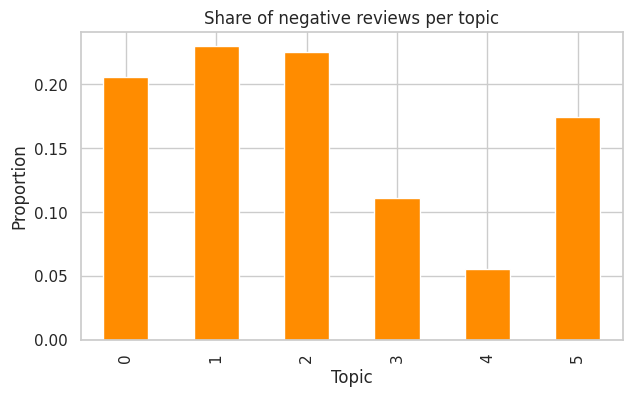

,topic,review
26660,0,"""I&#039;m going on month 3 on Jolessa and the bleeding hasn&#039;t stopped since the month prior. As a BC, its great cause I&#039;m not pregnant but the bleeding sucks. I haven&#039;t gained any weight which is great but I&#039;ve become super ir..."
112041,0,"""Do not use this form of birth control! I have had it for 2 months and I&rsquo;ve taken it out after a week each time due to increased blood pressure, anxiety, depression, and insomnia. I&rsquo;ve been on the pill and had depo no issues in the pa..."
102028,1,"""I had a bad reaction to an anti-inflammatory misdiagnosed as bipolar and was put on this drug. It causes psychoses in someone wrongly put on it."""
45434,1,"""I started this medication at a very low dose and experienced nausea, lethargy and dizziness. My doctor told me this was a good sign that the medication was working. I then started to lose control over my thinking and could not focus. My doctor t..."
106988,2,"""Was on Janumet for 8 years, kidney function had gone down and wanted a change. 7.2 A1c on most recent test before starting Victoza. Started .6 and am now at 1.8. Blood sugars are running twice as high from my Janumet, Was between 90-200 before. ..."
38820,2,"""I wrote a review on 12/2015 unfortunately I had to stop using copaxone because I got bad reactions. The last one was body shaking like if I had a machine connected to my body for one hour my buttocks muscle shaking so much. I got very scared and..."
129948,3,"""Taking Embel once a week now (Started the day before Christmas 12/24/16). I have had Ankylosing Spondylitis for over 17 years but was misdiagnosed until 3/15. The doctors always told me that I had chronic fatigue syndrome and fibromyalgia. It fi..."
46753,3,"""I&#039;m taking this as a last resort, have tried every med out there. Next stop is a Clinic in September. Have had migraines for more than 50 yrs."""
61667,4,"""Please please read !!!! When I was younger my skin was good I would get a pimple here and there as a common teen, but later I broke out not bad don&#039;t get me wrong but I broke out on my cheeks, a lot on my forehead. I would have tiny skin c..."
92561,4,"""Every time I&#039;ve used Abreva, it&#039;s knocked maybe 1 or 2 days off of the usual 10 days to 2 weeks of healing. I came here more to spread the word about LYSINE supplements. After tons of reading I heard about these pills and ran out to wh..."


In [6]:
assert 'train' in globals(), 'STOP: run Cell 1, Cell 2 and Cell 4 first'

neg = train[train['sentiment'] == 'negative']
neg_sample = neg.sample(n=min(8000, len(neg)), random_state=RANDOM_STATE).copy()

extra_stop = ['drug', 'medication', 'medicine', 'take', 'taking', 'took', 'day', 'month', 'week', 'year', 'time', 'get', 'got', 'would', 'one', 'also', 'like', 'even']
cv = CountVectorizer(max_df=0.5, min_df=10, max_features=3000, stop_words=extra_stop)
X_counts = cv.fit_transform(neg_sample['clean_review'])
feature_names = cv.get_feature_names_out()

results = [(k, LatentDirichletAllocation(n_components=k, learning_method='online', random_state=RANDOM_STATE, max_iter=5, batch_size=2048).fit(X_counts).perplexity(X_counts)) for k in [4, 6, 8]]
print('k and perplexity:', results)

best_k = 6
lda = LatentDirichletAllocation(n_components=best_k, learning_method='online', random_state=RANDOM_STATE, max_iter=10, batch_size=2048)
doc_topic = lda.fit_transform(X_counts)

print('\n'.join(['Topic ' + str(i) + ': ' + ', '.join(feature_names[c.argsort()[:-13:-1]]) for i, c in enumerate(lda.components_)]))

neg_sample['topic'] = doc_topic.argmax(axis=1)
share = neg_sample['topic'].value_counts(normalize=True).sort_index()
share.plot(kind='bar', color='darkorange', figsize=(7, 4))
plt.title('Share of negative reviews per topic')
plt.xlabel('Topic')
plt.ylabel('Proportion')
plt.show()

pd.set_option('display.max_colwidth', 250)
neg_sample.groupby('topic').head(2)[['topic', 'review']].sort_values('topic')

In [7]:
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split

RANDOM_STATE = 42

tr = train[train['sentiment'] != 'neutral'].copy()
te = test[test['sentiment'] != 'neutral'].copy()

tr['label'] = (tr['sentiment'] == 'positive').astype(int)
te['label'] = (te['sentiment'] == 'positive').astype(int)

X_tr, X_val, y_tr, y_val = train_test_split(tr['clean_review'], tr['label'], test_size=0.2, stratify=tr['label'], random_state=RANDOM_STATE)
X_test, y_test = te['clean_review'], te['label']

print('Train/Val/Test sizes:', len(X_tr), len(X_val), len(X_test))
print('Positive share (train):', round(y_tr.mean(), 3))

Train/Val/Test sizes: 117508 29377 48926
Positive share (train): 0.727


Total candidate features: 100000
Features with p < 0.05: 3741 of 100000
                 term        chi2       p_value
59233   not recommend  258.580944  3.498160e-58
97818           worse  239.208806  5.850896e-54
98021           worst  224.597439  8.986920e-51
59500       not worth  200.361890  1.741245e-45
38736        horrible  193.477485  5.537407e-44
8929         bleeding  170.265196  6.475083e-39
48825            love  150.024685  1.712238e-34
34884           great  138.481832  5.717609e-32
59489        not work  119.379121  8.650960e-28
86263        terrible  117.845437  1.874399e-27
8005             best  116.508227  3.678502e-27
93875           waste  105.226320  1.089530e-24
81360  stopped taking   98.986987  2.541664e-23
71128         removed   97.828084  4.563295e-23
11174          caused   94.504655  2.445168e-22
6104            awful   87.684466  7.677500e-21
3129          amazing   87.629944  7.892074e-21
98847            year   86.990696  1.090329e-20
57302      never

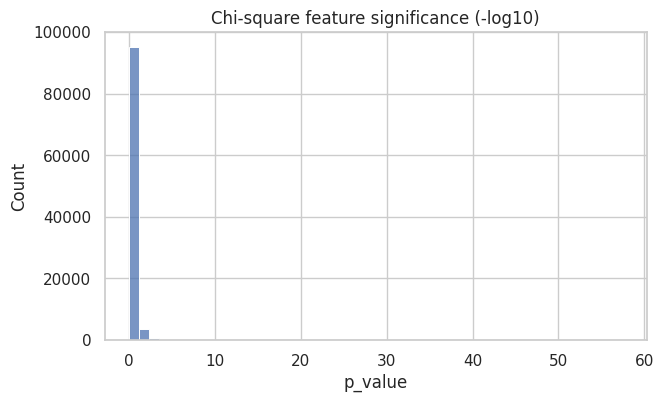

In [8]:
# TF-IDF changes every review into numeric word weights
tfidf = TfidfVectorizer(ngram_range=(1,2), min_df=5, max_features=100000,
sublinear_tf=True)
Xtr_tfidf = tfidf.fit_transform(X_tr)   #fit on the training data only which avoids leakage
terms = np.array(tfidf.get_feature_names_out())
print('Total candidate features:', Xtr_tfidf.shape[1])

# Chi-square test: does the words presence depend on the sentiment class?
chi_scores, p_values = chi2(Xtr_tfidf, y_tr)
chi_df = pd.DataFrame({'term': terms, 'chi2': chi_scores, 'p_value':
p_values}).dropna()

sig = chi_df[chi_df['p_value'] < 0.05]
print('Features with p < 0.05:', len(sig), 'of', len(chi_df))
print(chi_df.sort_values('chi2', ascending=False).head(20))

plt.figure(figsize=(7, 4))
sns.histplot(-np.log10(chi_df['p_value']+ 1e-300), bins=50)
plt.title('Chi-square feature significance (-log10)'); plt.show()




=== Baseline LogReg (validation) ===
              precision    recall  f1-score   support

    negative       0.80      0.66      0.72      8012
    positive       0.88      0.94      0.91     21365

    accuracy                           0.86     29377
   macro avg       0.84      0.80      0.82     29377
weighted avg       0.86      0.86      0.86     29377

ROC-AUC: 0.9163


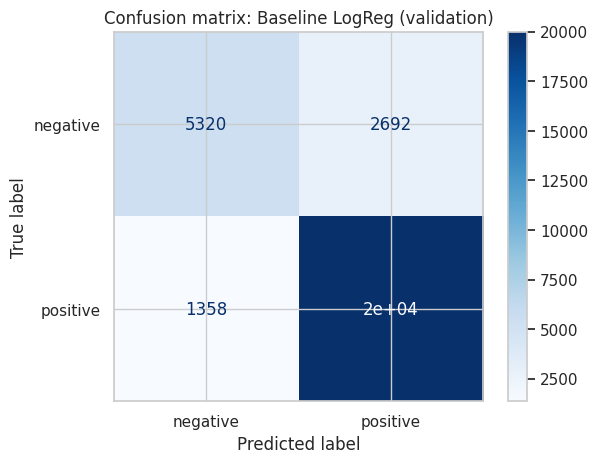


=== Multinomial NB (validation) ===
              precision    recall  f1-score   support

    negative       0.87      0.34      0.49      8012
    positive       0.80      0.98      0.88     21365

    accuracy                           0.81     29377
   macro avg       0.83      0.66      0.68     29377
weighted avg       0.82      0.81      0.77     29377

ROC-AUC: 0.8789


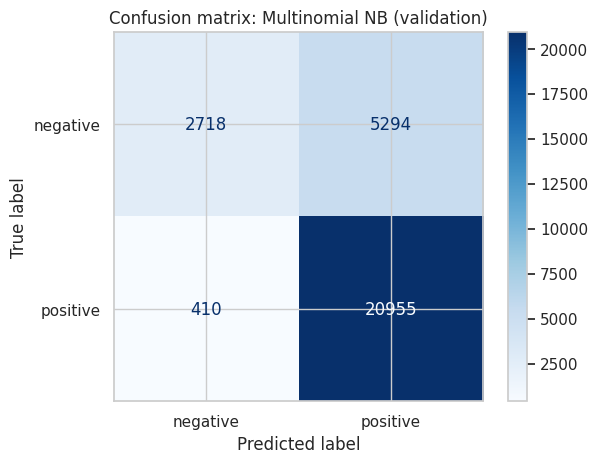

In [9]:
import matplotlib.pyplot as plt
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import MultinomialNB
from sklearn.pipeline import Pipeline
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, classification_report, roc_auc_score, ConfusionMatrixDisplay

def evaluate(model, X, y, name='Model'): pred = model.predict(X); prob = model.predict_proba(X)[:, 1]; res = {'model': name, 'accuracy': accuracy_score(y, pred), 'precision': precision_score(y, pred), 'recall': recall_score(y, pred), 'f1': f1_score(y, pred), 'f1_macro': f1_score(y, pred, average='macro'), 'roc_auc': roc_auc_score(y, prob)}; print('\n=== ' + name + ' ==='); print(classification_report(y, pred, target_names=['negative', 'positive'])); print('ROC-AUC:', round(res['roc_auc'], 4)); ConfusionMatrixDisplay.from_predictions(y, pred, display_labels=['negative', 'positive'], cmap='Blues'); plt.title('Confusion matrix: ' + name); plt.show(); return res

baseline = Pipeline([('tfidf', TfidfVectorizer(max_features=5000)), ('clf', LogisticRegression(max_iter=1000, random_state=RANDOM_STATE))])
baseline.fit(X_tr, y_tr)
res_base = evaluate(baseline, X_val, y_val, 'Baseline LogReg (validation)')

nb = Pipeline([('tfidf', TfidfVectorizer(max_features=5000)), ('clf', MultinomialNB())])
nb.fit(X_tr, y_tr)
res_nb = evaluate(nb, X_val, y_val, 'Multinomial NB (validation)')

Fitting 3 folds for each of 16 candidates, totalling 48 fits
Best parameters: {'clf__C': 5, 'clf__class_weight': 'balanced', 'select__k': 10000, 'tfidf__ngram_range': (1, 2)}
Best CV F1 macro: 0.8112

=== Tuned LogReg (validation) ===
              precision    recall  f1-score   support

    negative       0.72      0.86      0.78      8012
    positive       0.94      0.87      0.91     21365

    accuracy                           0.87     29377
   macro avg       0.83      0.87      0.84     29377
weighted avg       0.88      0.87      0.87     29377

ROC-AUC: 0.9409


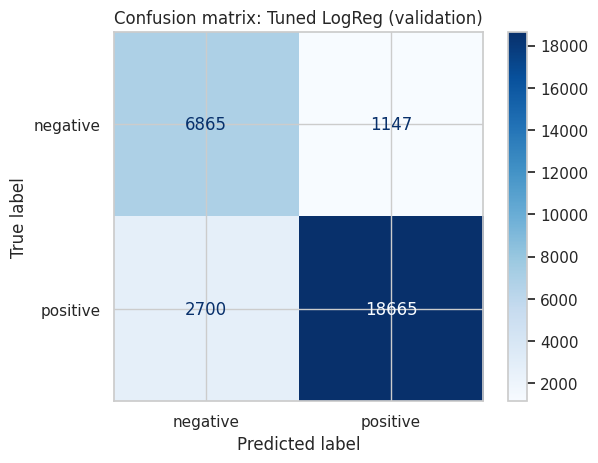

In [10]:
import pandas as pd
from sklearn.base import clone
from sklearn.model_selection import GridSearchCV
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.feature_selection import SelectKBest, chi2
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline

# Pipeline: TF-IDF -> chi-square feature selection -> Logistic Regression
pipe = Pipeline([('tfidf', TfidfVectorizer(sublinear_tf=True, min_df=5, max_features=50000)), ('select', SelectKBest(chi2)), ('clf', LogisticRegression(max_iter=2000, random_state=RANDOM_STATE))])

# Parameters to attempt (16 combinations)
param_grid = {'tfidf__ngram_range': [(1, 1), (1, 2)], 'select__k': [3000, 10000], 'clf__C': [1, 5], 'clf__class_weight': [None, 'balanced']}

# Tune on a 20,000-review sample for quickness
X_sub = X_tr.sample(20000, random_state=RANDOM_STATE)
y_sub = y_tr.loc[X_sub.index]

# 3-fold cross-validation, scored on macro F1 (treats both classes equally)
grid = GridSearchCV(pipe, param_grid, cv=3, scoring='f1_macro', n_jobs=-1, verbose=1)
grid.fit(X_sub, y_sub)
print('Best parameters:', grid.best_params_)
print('Best CV F1 macro:', round(grid.best_score_, 4))

# Retrain the optimal settings on the complete training data
best_model = clone(pipe).set_params(**grid.best_params_)
best_model.fit(X_tr, y_tr)

res_best = evaluate(best_model, X_val, y_val, 'Tuned LogReg (validation)')

# Compare baseline, Naive Bayes and tuned model
comparison = pd.DataFrame([res_base, res_nb, res_best]).round(4)


=== Tuned LogReg (TEST) ===
              precision    recall  f1-score   support

    negative       0.72      0.86      0.79     13495
    positive       0.94      0.87      0.91     35431

    accuracy                           0.87     48926
   macro avg       0.83      0.87      0.85     48926
weighted avg       0.88      0.87      0.87     48926

ROC-AUC: 0.9416


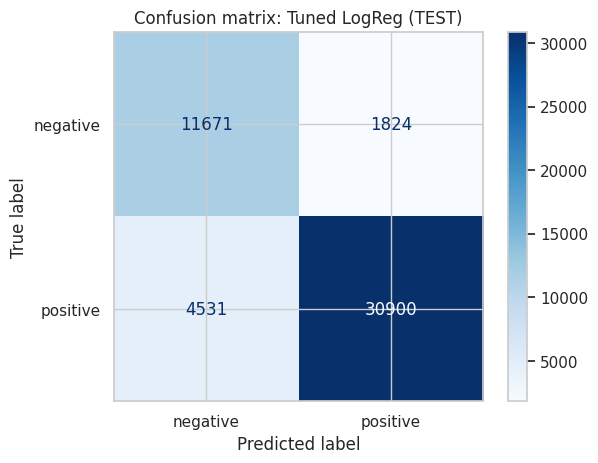

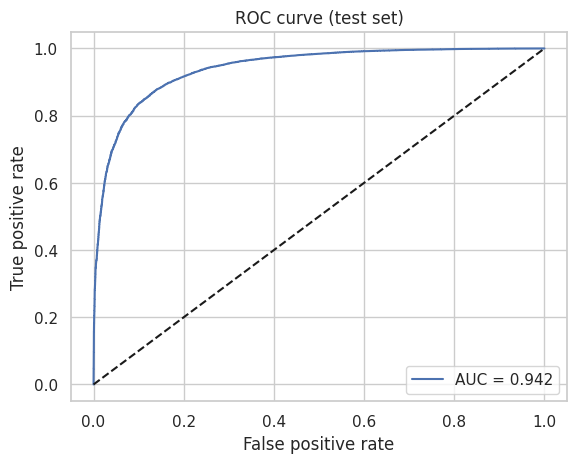

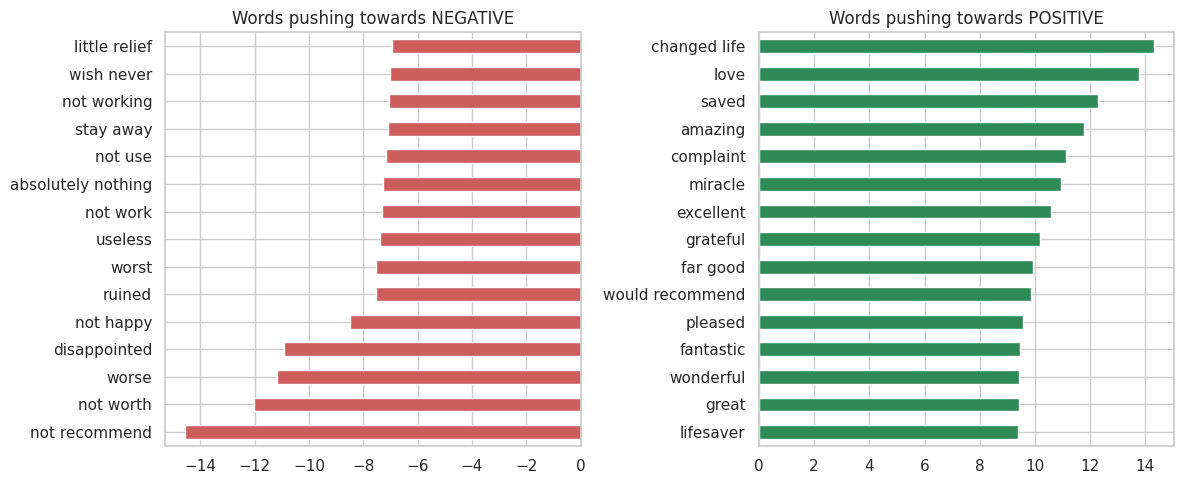

sentiment
positive    0.662
negative    0.249
neutral     0.089
Name: proportion, dtype: float64
Error rate: 0.1299
* "Went in for a colonoscopy yesterday. I was pretty anxious but they reassured me that I would fall asleep within 20 seconds and wake up and ask when I&#039;m having the procedure. They had me turn over on my side and told me they were administering the propofol, and there may be a burning sensation.

* "Try it and see for yourself!!!"

* "I&#039;ve been on Prozac for a little over a year for depression and anxiety. I&#039;m on 20mg since I was 14. Personally I think it was too much for my system when I first started taking it. I was like an ADHD child. Couldn&#039;t calm down. Jumping around everywhere and could barely sleep at nigh


In [11]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve

# 1. final test outcome (the test set is employed only here)
res_test = evaluate(best_model, X_test, y_test, 'Tuned LogReg (TEST)')

# 2. ROC curve
fpr, tpr, _ = roc_curve(y_test, best_model.predict_proba(X_test)[:, 1])
plt.plot(fpr, tpr, label='AUC = ' + str(round(res_test['roc_auc'], 3)))
plt.plot([0, 1], [0, 1], 'k--')
plt.xlabel('False positive rate')
plt.ylabel('True positive rate')
plt.title('ROC curve (test set)')
plt.legend()
plt.show()

# 3. Words that push towards negative or positive sentiment
vec = best_model.named_steps['tfidf']
sel = best_model.named_steps['select']
clf = best_model.named_steps['clf']
names = np.array(vec.get_feature_names_out())[sel.get_support()]
coef = pd.Series(clf.coef_[0], index=names).sort_values()

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
coef.head(15).plot(kind='barh', ax=axes[0], color='indianred')
axes[0].set_title('Words pushing towards NEGATIVE')
coef.tail(15).plot(kind='barh', ax=axes[1], color='seagreen')
axes[1].set_title('Words pushing towards POSITIVE')
plt.tight_layout()
plt.show()

# 4. Overall sentiment of the whole customer base
print(pd.concat([train['sentiment'], test['sentiment']]).value_counts(normalize=True).round(3))

# 5. read mistakes to understand limitations
test_check = te.copy()
test_check['pred'] = best_model.predict(X_test)
errors = test_check[test_check['pred'] != test_check['label']]
print('Error rate:', round(len(errors) / len(test_check), 4))
print('\n\n'.join(['* ' + r[:300] for r in errors['review'].sample(3, random_state=RANDOM_STATE)]))


In [12]:
# Average rating of negative reviews for each topic displays which concern needs the most attention
print(neg_sample.groupby('topic')['rating'].mean(['count', 'mean']).round(2))


topic
0    2.18
1    1.87
2    1.74
3    1.76
4    1.85
5    1.75
Name: rating, dtype: float64


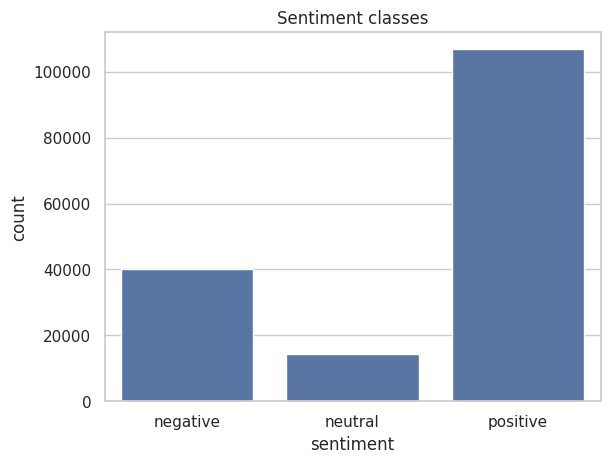

In [13]:
sns.countplot(x='sentiment', data=train, order=['negative','neutral','positive'])
plt.title('Sentiment classes'); plt.show()

Report is on the Word document that was handed in with the notebook.